## 1. Imports and Config

In [8]:
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.metrics import (
    classification_report, confusion_matrix, roc_auc_score,
    roc_curve, precision_recall_curve, average_precision_score,
    ConfusionMatrixDisplay
)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
import warnings
warnings.filterwarnings('ignore')

artifacts = joblib.load('eda_artifacts.pkl')
df = artifacts['df']
num_features = artifacts['num_features']
iso_anomaly = artifacts['iso_anomaly']

print('Data loaded from EDA.')

Data loaded from EDA.


---
## 2. Data Preparation

In [9]:
df_model = df[num_features + ['Type', 'Target']].copy()
df_model = pd.get_dummies(df_model, columns=['Type'], drop_first=False)

feature_cols = [c for c in df_model.columns if c != 'Target']
X_all = df_model[feature_cols].values
y_all = df_model['Target'].values

X_train_calib, X_test, y_train_calib, y_test = train_test_split(
    X_all, y_all, test_size=0.15, random_state=17, stratify=y_all
)
X_train, X_calib, y_train, y_calib = train_test_split(
    X_train_calib, y_train_calib, test_size=0.176, random_state=17, stratify=y_train_calib
)
# 0.176 * 0.85 ≈ 0.15  ->  train≈70%, calib≈15%, test≈15%

scaler = StandardScaler()
X_train_sc       = scaler.fit_transform(X_train)
X_calib_sc       = scaler.transform(X_calib)
X_test_sc        = scaler.transform(X_test)
X_train_calib_sc = scaler.transform(X_train_calib)

print(f'Train: {X_train.shape[0]} samples')
print(f'Calib: {X_calib.shape[0]} samples')
print(f'Test:  {X_test.shape[0]} samples')
print(f'Train failures: {y_train.sum()} ({y_train.mean()*100:.1f}%)')
print(f'Calib failures: {y_calib.sum()} ({y_calib.mean()*100:.1f}%)')
print(f'Test  failures: {y_test.sum()}  ({y_test.mean()*100:.1f}%)')
print(f'\nFeatures: {len(feature_cols)}\n{feature_cols}')

Train: 7004 samples
Calib: 1496 samples
Test:  1500 samples
Train failures: 237 (3.4%)
Calib failures: 51 (3.4%)
Test  failures: 51  (3.4%)

Features: 8
['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Type_H', 'Type_L', 'Type_M']


---
## 3. Hyperparameter Tuning - Optimal k

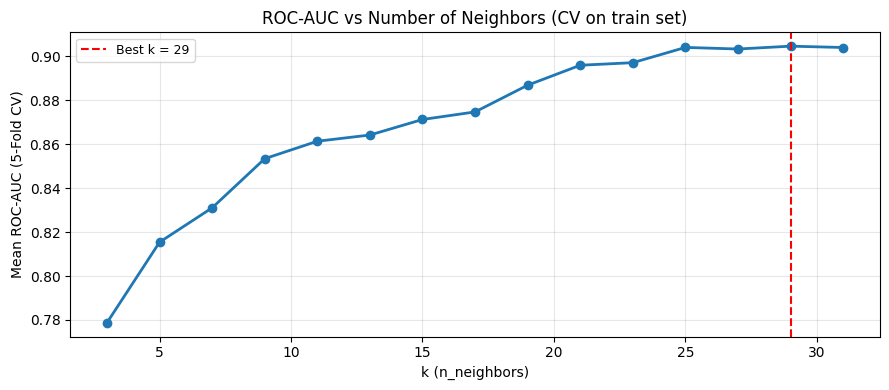

Best k: 29  (ROC-AUC = 0.9047


In [10]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=17)

k_candidates = list(range(3, 32, 2))  # odd values only to avoid ties
mean_aucs = []

for k in k_candidates:
    knn_pipe = Pipeline([
        ('scaler', StandardScaler()),
        ('knn', KNeighborsClassifier(n_neighbors=k, weights='distance', metric='minkowski', p=2))
    ])
    cv_res = cross_validate(
        knn_pipe, X_train, y_train, cv=cv,
        scoring='roc_auc', return_train_score=False
    )
    mean_aucs.append(cv_res['test_score'].mean())

best_k = k_candidates[np.argmax(mean_aucs)]

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(k_candidates, mean_aucs, marker='o', lw=2)
ax.axvline(best_k, color='red', linestyle='--', lw=1.5, label=f'Best k = {best_k}')
ax.set_title('ROC-AUC vs Number of Neighbors (CV on train set)')
ax.set_xlabel('k (n_neighbors)')
ax.set_ylabel('Mean ROC-AUC (5-Fold CV)')
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f'Best k: {best_k}  (ROC-AUC = {max(mean_aucs):.4f}')

---
## 4. Training and Basic Evaluation

In [11]:
knn = KNeighborsClassifier(
    n_neighbors=best_k,
    weights='distance',
    metric='minkowski',
    p=2
)
knn.fit(X_train_sc, y_train)

y_pred  = knn.predict(X_test_sc)
y_proba = knn.predict_proba(X_test_sc)[:, 1]

print('- Classification Report -')
print(classification_report(y_test, y_pred, target_names=['No Failure', 'Failure']))

roc_auc  = roc_auc_score(y_test, y_proba)
avg_prec = average_precision_score(y_test, y_proba)
print(f'ROC-AUC: {roc_auc:.4f}')
print(f'Average Precision: {avg_prec:.4f}')

- Classification Report -
              precision    recall  f1-score   support

  No Failure       0.97      1.00      0.98      1449
     Failure       1.00      0.12      0.21        51

    accuracy                           0.97      1500
   macro avg       0.98      0.56      0.60      1500
weighted avg       0.97      0.97      0.96      1500

ROC-AUC: 0.9534
Average Precision: 0.6516


---
## 5. Confusion Matrix

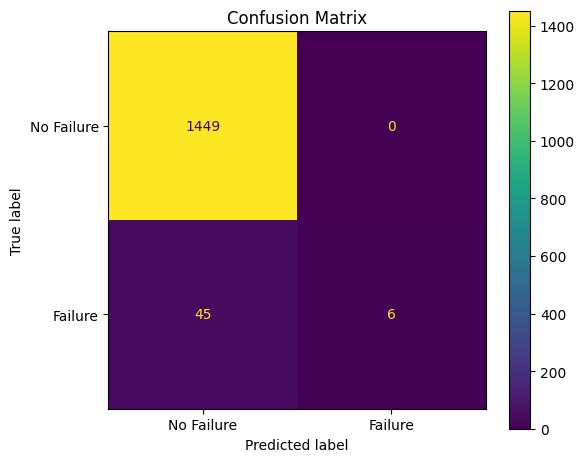


False Alarm Rate: 0.000
Miss Rate: 0.882


In [12]:
fig, ax = plt.subplots(figsize=(6, 5))
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(cm, display_labels=['No Failure', 'Failure'])
disp.plot(ax=ax)
ax.set_title('Confusion Matrix')
plt.tight_layout()
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f'\nFalse Alarm Rate: {fp/(fp+tn):.3f}')
print(f'Miss Rate: {fn/(fn+tp):.3f}')

---
## 6. ROC Curve and Precision-Recall Curve

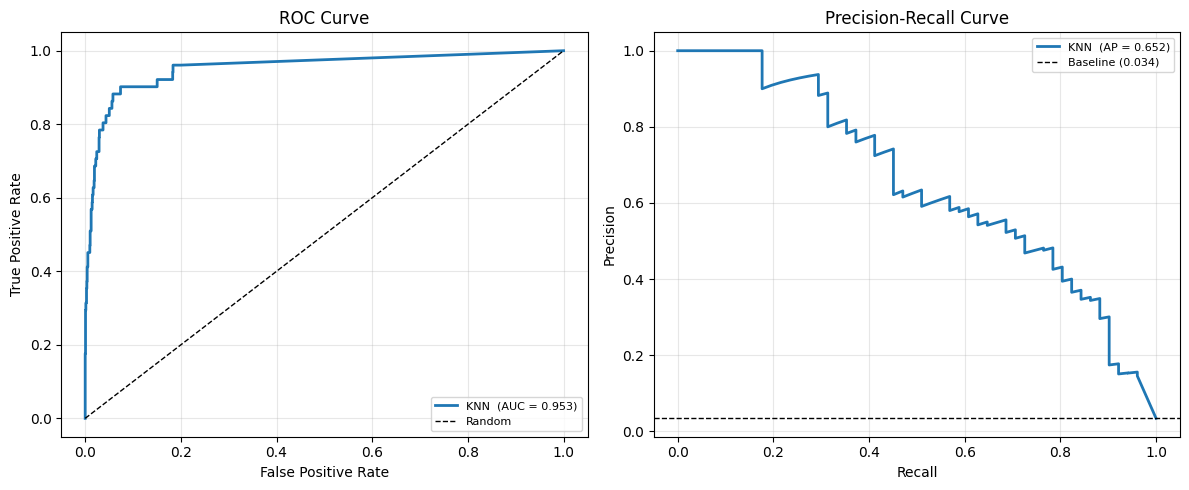

In [13]:
fpr, tpr, _ = roc_curve(y_test, y_proba)
prec, rec, _ = precision_recall_curve(y_test, y_proba)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# ROC
ax = axes[0]
ax.plot(fpr, tpr, lw=2, label=f'KNN  (AUC = {roc_auc:.3f})')
ax.plot([0, 1], [0, 1], 'k--', lw=1, label='Random')
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title('ROC Curve')
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)

# Precision-Recall
ax = axes[1]
ax.plot(rec, prec, lw=2, label=f'KNN  (AP = {avg_prec:.3f})')
baseline = y_test.mean()
ax.axhline(baseline, color='k', linestyle='--', lw=1, label=f'Baseline ({baseline:.3f})')
ax.set_xlabel('Recall')
ax.set_ylabel('Precision')
ax.set_title('Precision-Recall Curve')
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

---
## 7. Cross-validation (Stratified 5-Fold)

In [14]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=17)

knn_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('knn', KNeighborsClassifier(
        n_neighbors=best_k, weights='distance', metric='minkowski', p=2
    ))
])

cv_results = cross_validate(
    knn_pipeline, X_train_calib, y_train_calib, cv=cv,
    scoring=['roc_auc', 'average_precision', 'f1', 'recall', 'precision'],
    return_train_score=False
)

metrics = {
    'ROC-AUC': cv_results['test_roc_auc'],
    'Avg Precision': cv_results['test_average_precision'],
    'F1 (Failure)': cv_results['test_f1'],
    'Recall (Failure)': cv_results['test_recall'],
    'Precision (Failure)': cv_results['test_precision'],
}

print('- Cross-Validation Results (5-Fold on train+calib set) -')
print(f'{"Metric":<23} {"Mean":>8} {"Std":>8} {"Min":>8} {"Max":>8}')
print('-' * 60)
for name, vals in metrics.items():
    print(f'{name:<25} {vals.mean():>8.4f} {vals.std():>8.4f} {vals.min():>8.4f} {vals.max():>8.4f}')


- Cross-Validation Results (5-Fold on train+calib set) -
Metric                      Mean      Std      Min      Max
------------------------------------------------------------
ROC-AUC                     0.9203   0.0326   0.8792   0.9648
Avg Precision               0.5840   0.0618   0.4670   0.6412
F1 (Failure)                0.1207   0.0661   0.0667   0.2121
Recall (Failure)            0.0660   0.0387   0.0345   0.1207
Precision (Failure)         0.9750   0.0500   0.8750   1.0000
